# Astro Data Lab: a walkthrough

This notebook takes you through the whole platform on **real TESS data**. It writes no pipeline code of its
own: every step calls the same functions that the `astro-data-lab` command uses. What you write here is
only what a model builder would write: a model, and an experiment definition.

1. Check the setup (database, GPU, MLflow).
2. See what data and labels exist.
3. Look at a labelled light curve, and at what the model actually receives.
4. See how synthetic transits are injected.
5. Write your own PyTorch model and check it follows the contract.
6. Define an experiment and **train it with the platform**.
7. Monitor it, evaluate it on unseen stars, and classify a single FITS file.
8. Move from the notebook to a real, long run.

**The question every model answers:** *does this complete light curve contain a transit-like signal?*

| section | platform functions used | module |
|---|---|---|
| 1 | `Settings.from_env`, `ensure_schema`, `connect` | `config.py`, `database/` |
| 2 | `labels.summary` | `data/labels.py` |
| 3 | `labels.fixed_sample`, `prepare_many`, `curve_arrays`, `transit_centres`, `transit_readings`, `model_input` | `data/` |
| 4 | `inject_transit`, `detrend` | `data/lightcurves.py` |
| 5 | `LightCurveCNN`, `PatchTransformer`, `check_model` | `models/` |
| 6 | `Experiment`, `delete_run`, `train` | `config.py`, `training/trainer.py` |
| 7 | `status`, `history`, `evaluate`, `download_fits`, `predict` | `training/`, `data/`, `predict.py` |

**Before running:** `uv sync`, a filled-in `.env` in the repo root, and at least one `astro-data-lab sync`.
No other training run can be active, because the platform runs one trainer per machine. The training demo
downloads a few hundred curves, about 10 minutes on a typical home connection.

## 1. Setup

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from dotenv import load_dotenv
from torch import nn

load_dotenv(Path.cwd().parent / ".env")  # the same settings the command line uses

from astro_data_lab.config import TARGETS, Experiment, Settings
from astro_data_lab.data import labels
from astro_data_lab.data.lightcurves import (
    curve_arrays, detrend, inject_transit, model_input, prepare_many, transit_centres, transit_readings,
)
from astro_data_lab.database import connect, ensure_schema
from astro_data_lab.models import LightCurveCNN, PatchTransformer, check_model

settings = Settings.from_env()
ensure_schema()
with connect() as conn:
    print("database:", conn.execute("SELECT current_database()").fetchone()[0], "OK")
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (CPU training is slow)")
print("data directory:", settings.data_dir, "| MLflow:", settings.mlflow_uri, "experiment", settings.mlflow_experiment)
print("classes:", TARGETS["transit"])

database: astro_lab OK
GPU: NVIDIA GeForce RTX 2060
data directory: /data/astro-data-lab | MLflow: http://127.0.0.1:5000 experiment tess-classifiers
classes: ('no_signal', 'signal')


## 2. What data is there?

`astro-data-lab sync` fills two things:
- the **manifest**: every TESS light-curve file at MAST (metadata only, nothing downloaded);
- the **planet catalogues**: confirmed planets and TESS Objects of Interest (TOIs), including each TOI's transit
  timing (epoch, period, duration).

Labels (`data/labels.py`):
- **signal**: the star is a TOI (candidate, planet or false positive such as an eclipsing binary), *and* one
  of its predicted transits falls inside this curve's readings. That is checked after download.
- **no_signal**: the star is in neither catalogue.
- Everything else is left out, for example confirmed planets that never transit in TESS data.

Stars, not curves, are split 80/10/10 into train/validation/test with a fixed hash of the star ID. Every run uses
the same split, and the model is always scored on stars it never trained on.

`labels.summary` counts usable curves per class and split. The "signal" counts are before the per-curve
transit check, which keeps about 87% of them.

In [3]:
with connect() as conn:
    table = labels.summary(conn)
table

,train,validation,test
no_signal,432300,53740,53444
signal,4991,573,648


## 3. A labelled curve, and what the model sees

`fixed_sample` returns the same curves every time; `prepare_many` downloads anything not cached, confirms each
label (a "signal" curve must contain a predicted transit), and skips unusable files instead of failing.
`curve_arrays` reads a prepared curve's cleaned readings, and `transit_centres` gives the predicted transit
times from the TOI catalogue.

prepared 18 curves; 2 signal candidates had no transit in their curve
signal curve: 18,653 readings over 27.3 days; 1 predicted transits of 7.2 h; 215 readings fall inside them


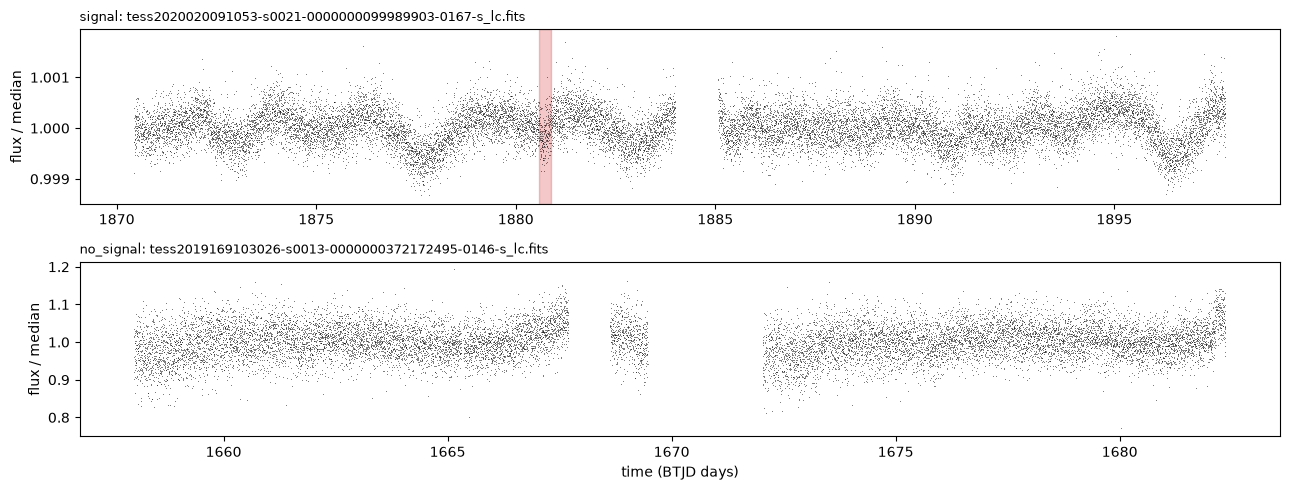

In [3]:
with connect() as conn:
    sample = labels.fixed_sample(conn, "transit", "validation", per_class=10)
prepared = prepare_many(sample, settings, workers=8)
signal = next(c for c in prepared.curves if c.target == labels.SIGNAL)
quiet = next(c for c in prepared.curves if c.target == labels.NO_SIGNAL)
print(f"prepared {len(prepared.curves)} curves; {prepared.no_transit} signal candidates had no transit in their curve")

time, flux = curve_arrays(signal, settings)
centres = transit_centres(time, signal.ephemerides)
duration = signal.ephemerides[0][2]
centre = max(centres, key=lambda c: np.sum(np.abs(time - c) < duration / 2))  # best-covered transit, used below
print(f"signal curve: {len(time):,} readings over {time[-1] - time[0]:.1f} days; {len(centres)} predicted transits "
      f"of {duration * 24:.1f} h; {transit_readings(time, signal.ephemerides)} readings fall inside them")

fig, axes = plt.subplots(2, 1, figsize=(13, 5))
for ax, curve, title in ((axes[0], signal, "signal"), (axes[1], quiet, "no_signal")):
    t, f = curve_arrays(curve, settings)
    ax.plot(t, f, ",k", alpha=0.5)
    ax.set_title(f"{title}: {curve.data_uri.split('/')[-1]}", loc="left", fontsize=9)
    ax.set_ylabel("flux / median")
for c in centres:  # red = predicted transits
    axes[0].axvspan(c - duration / 2, c + duration / 2, color="tab:red", alpha=0.25)
axes[1].set_xlabel("time (BTJD days)")
plt.tight_layout()

Each curve becomes a `(4, readings)` tensor (`model_input`):

| channel | meaning |
|---|---|
| 0 | brightness change in % (raw) |
| 1 | **detrended** brightness in units of the curve's noise (slow stellar variability removed; transits kept) |
| 2 | log of the time gap before each reading |
| 3 | 1 = real reading, 0 = padding (minibatches pad curves to equal length) |

Zooming into one predicted transit shows why channel 1 matters.

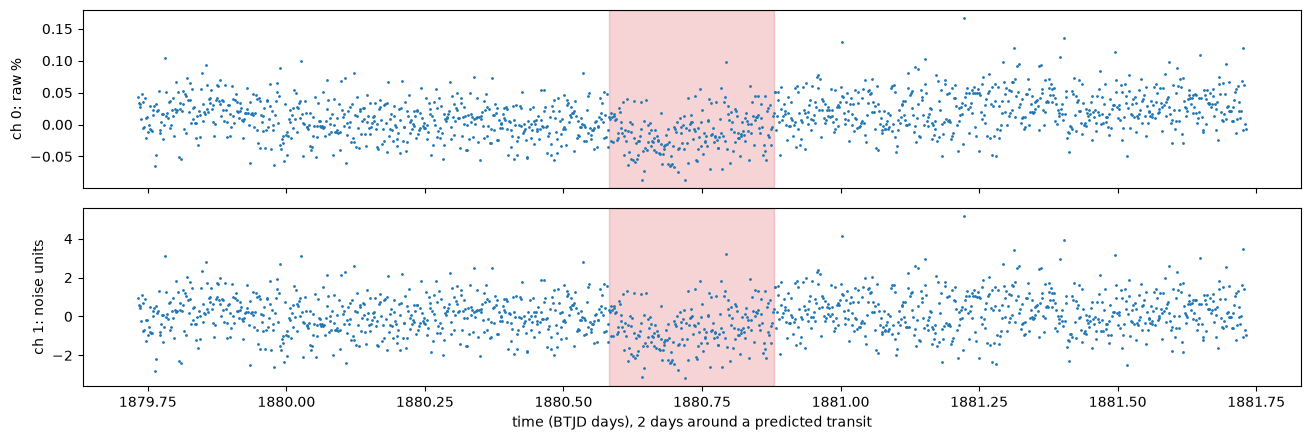

In [4]:
inputs = model_input(time, flux)
window = np.abs(time - centre) < 1.0
fig, axes = plt.subplots(2, 1, figsize=(13, 4.5), sharex=True)
axes[0].plot(time[window], inputs[0, window], ".", ms=2); axes[0].set_ylabel("ch 0: raw %")
axes[1].plot(time[window], inputs[1, window], ".", ms=2); axes[1].set_ylabel("ch 1: noise units")
for ax in axes:
    ax.axvspan(centre - duration / 2, centre + duration / 2, color="tab:red", alpha=0.2)
axes[1].set_xlabel("time (BTJD days), 2 days around a predicted transit")
plt.tight_layout()

## 4. Synthetic transits

There are only about 4,000 real "signal" training curves, and a model trained on them alone soon memorises
them. So each training round also takes some of its fresh no_signal curves and adds a synthetic transit
(`inject_transit`): period 0.5-15 days, duration 1-8 hours, depth set for a signal-to-noise of 8-40. The model
sees the *same star* with and without a transit, so it has to learn the transit, not the star. Validation and
test sets use **real** curves only.

injected: period 4.19 d, duration 7.3 h, depth 1.864%


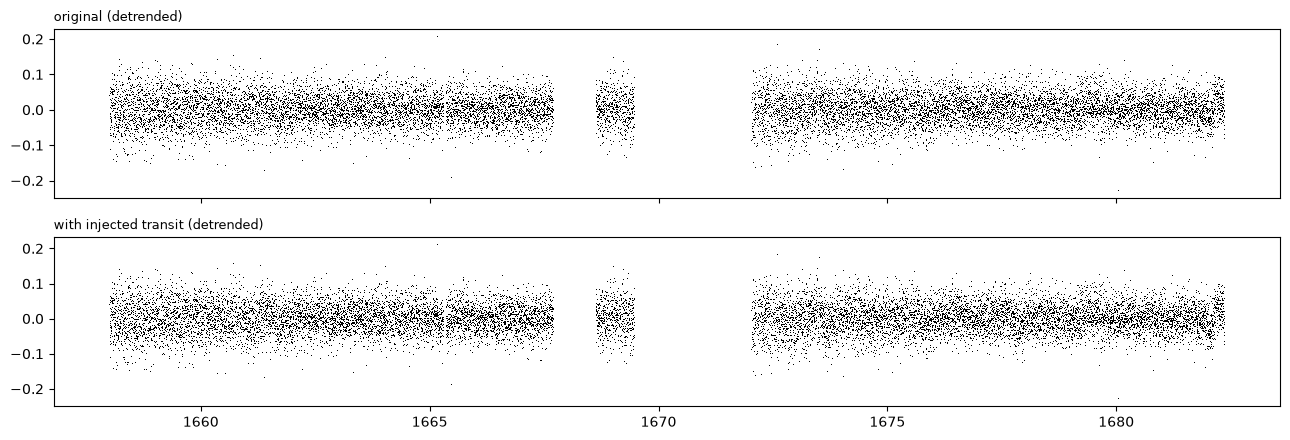

In [5]:
t, f = curve_arrays(quiet, settings)
new_flux, (inj_epoch, inj_period, inj_duration) = inject_transit(t, f, seed=7)
print(f"injected: period {inj_period:.2f} d, duration {inj_duration * 24:.1f} h, "
      f"depth {(1 - new_flux / f).max() * 100:.3f}%")
fig, axes = plt.subplots(2, 1, figsize=(13, 4.5), sharex=True)
axes[0].plot(t, detrend(t, f), ",k"); axes[0].set_title("original (detrended)", loc="left", fontsize=9)
axes[1].plot(t, detrend(t, new_flux), ",k"); axes[1].set_title("with injected transit (detrended)", loc="left", fontsize=9)
plt.tight_layout()

## 5. Models

The only contract:

```python
model = YourModel(num_classes=2, **options)        # an nn.Module
logits = model(inputs)   # (batch, 4, readings) -> (batch, 2), raw scores, no softmax
```

The model must ignore padding (channel 3 = 0). `check_model` verifies shape, finiteness and padding
invariance in under a second. Two examples come with the platform:
- `LightCurveCNN`: masked 1-D convolutions that shrink the curve 256×, then mean+max pooling.
- `PatchTransformer`: cuts the curve into ~2-hour patches, then self-attention across the whole sector.
  This is also the natural backbone for a foundation model (see the README).

In [6]:
for model in (LightCurveCNN(num_classes=2), PatchTransformer(num_classes=2)):
    check_model(model, 2)
    print(f"{type(model).__name__}: {sum(p.numel() for p in model.parameters()):,} parameters, contract OK")

LightCurveCNN: 146,754 parameters, contract OK


PatchTransformer: 343,618 parameters, contract OK


Now write your own. `DipDetector` is the classic transit-search idea as a tiny network: slide learned
"dip templates" along the detrended curve (a **matched filter**) and report how strongly and how often they
fire. It has about 2,000 parameters.

In [7]:
class DipDetector(nn.Module):
    def __init__(self, num_classes: int, templates: int = 16, length: int = 121):
        super().__init__()
        self.match = nn.Conv1d(1, templates, length, padding=length // 2)  # ~4 hours at 2-min cadence
        self.head = nn.Linear(2 * templates, num_classes)

    def forward(self, inputs):
        valid = inputs[:, 3:4] > 0
        response = torch.relu(self.match(inputs[:, 1:2] * valid))           # detrended channel only
        strongest = response.masked_fill(~valid, 0).amax(-1)                # best match anywhere
        average = (response * valid).sum(-1) / valid.sum(-1)                # how often it fires
        return self.head(torch.cat((strongest, average), dim=1))


check_model(DipDetector(num_classes=2), 2)
print("DipDetector:", sum(p.numel() for p in DipDetector(2).parameters()), "parameters, contract OK")

DipDetector: 2018 parameters, contract OK


## 6. Define an experiment and train it with the platform

An `Experiment` is everything that defines a run; its `name` identifies the run in PostgreSQL, MLflow and the
checkpoint folder. In a TOML file it looks like `experiments/transit_cnn.toml`; here it is built directly.

`factory="__main__:DipDetector"` points at the class defined in this notebook. That works while this notebook's
kernel is running. For real runs, move the class into `src/astro_data_lab/models/` (section 8).

These settings are **deliberately tiny** (3 rounds of 128 curves) so the demo takes minutes. Do not expect a good
model from it. The point is to see every step happen.

`delete_run` forgets any earlier run with the same name, so this notebook starts fresh each time it runs.

In [8]:
from astro_data_lab.training.trainer import delete_run, history, status, train

experiment = Experiment(
    name="notebook-dip-detector",
    factory="__main__:DipDetector",
    options={"templates": 16},
    curves_per_round=128,           # 64 signal (half injected) + 64 no_signal per round
    injected_fraction=0.5,
    passes_per_round=3,
    rounds=3,
    validation_curves_per_class=40,
    learning_rate=3e-3,
)
delete_run(experiment.name, settings)
experiment

Experiment(name='notebook-dip-detector', target='transit', curves_per_round=128, injected_fraction=0.5, rounds=3, validation_curves_per_class=40, download_workers=8, max_bad_fraction=0.2, passes_per_round=3, minibatch_size=32, learning_rate=0.003, weight_decay=0.0001, seed=42, factory='__main__:DipDetector', options={'templates': 16})

`train` is exactly what `astro-data-lab train` runs. Each round downloads fresh no_signal curves (the next
round downloads while this one trains), trains, scores the validation stars, saves a checkpoint, and logs to
MLflow. Stopping (interrupt the kernel) is safe: calling `train` again resumes.

In [9]:
train(experiment, settings)

Model __main__:DipDetector: 2,018 parameters on cuda.


Preparing validation curves from stars never used for training...


Checking 4,991 signal training curves for a transit inside the readings (downloads once, then cached)...


  4,352 contain a transit; 639 do not and are left out.


Training curves per class: no_signal=432,355 (streamed), signal=4,352 (cached, re-sampled)


🏃 View run notebook-dip-detector at: http://127.0.0.1:5000/#/experiments/6/runs/e7e6713b9afa41f2bcc472c4491f1860
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/6


Round 1: 128 curves (32 injected), 12 steps, train loss 0.753 | validation balanced acc 0.562 (chance 0.500), macro F1 0.496 *best* | GPU 0s, waited 9s for data


Round 2: 128 curves (32 injected), 12 steps, train loss 0.715 | validation balanced acc 0.475 (chance 0.500), macro F1 0.470 | GPU 0s, waited 8s for data


Round 3: 128 curves (32 injected), 12 steps, train loss 0.667 | validation balanced acc 0.488 (chance 0.500), macro F1 0.366 | GPU 0s, waited 12s for data


🏃 View run notebook-dip-detector at: http://127.0.0.1:5000/#/experiments/6/runs/e7e6713b9afa41f2bcc472c4491f1860
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/6


## 7. Monitor, evaluate, predict

`status` reads progress from PostgreSQL. `history` returns every per-round metric from MLflow as a table,
one row per round; open the MLflow UI to compare runs side by side.

Run 'notebook-dip-detector' (target: transit), last saved 2026-11-01 23:54
  rounds completed: 3
  examples trained: 384 (288 distinct curves)
  best validation balanced accuracy: 0.562
  best checkpoint: /data/astro-data-lab/checkpoints/notebook-dip-detector/best.pt
  curves excluded as unusable (all runs): 16


,train_loss,validation_balanced_accuracy,validation_macro_f1,waiting_for_data_seconds
round,,,,
1,0.752783,0.5625,0.496312,9.239707
2,0.714635,0.4750,0.469697,8.232647
3,0.667267,0.4875,0.366184,12.104667


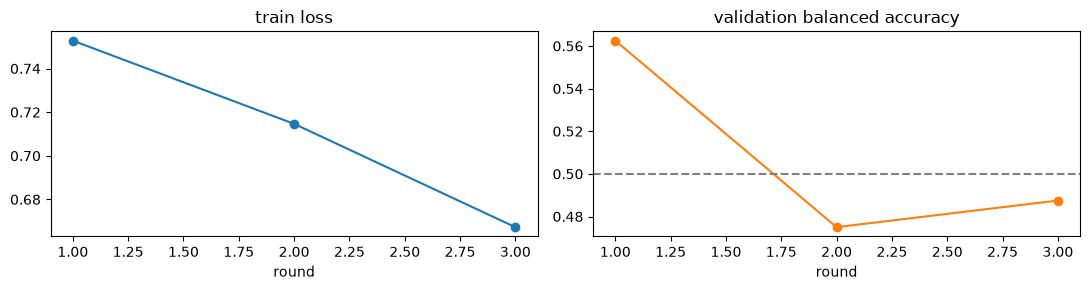

In [10]:
status(experiment.name)
metrics = history(experiment.name, settings)
axes = metrics[["train_loss", "validation_balanced_accuracy"]].plot(subplots=True, layout=(1, 2), figsize=(11, 3),
                                                                     marker="o", legend=False, title=["train loss", "validation balanced accuracy"])
axes.flat[1].axhline(0.5, ls="--", c="grey")
plt.tight_layout()
metrics[["train_loss", "validation_balanced_accuracy", "validation_macro_f1", "waiting_for_data_seconds"]]

**Evaluate** scores the best checkpoint on **test** stars: never trained on, never used to pick a checkpoint.
Balanced accuracy of 0.5 is guessing. The verdict line says "BETTER THAN CHANCE" only if the whole 95%
confidence interval is above 0.5. Use the test split once per model, when you are done tuning.

In [11]:
from astro_data_lab.training.evaluation import evaluate

report = evaluate(experiment.name, settings, split="test")

Preparing test curves from stars never used for training...



notebook-dip-detector, round 1 checkpoint, test stars:
Balanced accuracy 0.688 (95% CI 0.612-0.761); chance = 0.500 -> BETTER THAN CHANCE
Macro F1 0.654 | accuracy 0.688 | loss 0.590

true / predicted   no_signal      signal    recall  precision  curves
       no_signal          40           0     1.000      0.615      40
          signal          25          15     0.375      1.000      40
🏃 View run notebook-dip-detector at: http://127.0.0.1:5000/#/experiments/6/runs/e7e6713b9afa41f2bcc472c4491f1860
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/6


**Predict** classifies one complete FITS file, cleaned exactly like training data. `download_fits` fetches
one test star's raw file the same way training does (the public S3 copy first, then MAST).

In [12]:
import tempfile

import requests

from astro_data_lab.data.lightcurves import download_fits
from astro_data_lab.predict import predict

with connect() as conn:
    test_curve = next(c for c in labels.fixed_sample(conn, "transit", "test", per_class=1) if c.target == labels.SIGNAL)
with tempfile.TemporaryDirectory() as directory, requests.Session() as session:
    fits_path = download_fits(session, test_curve.data_uri, test_curve.size_bytes, Path(directory) / "lightcurve_lc.fits")
    result = predict(settings.checkpoints / experiment.name / "best.pt", fits_path)
result

{'tic_id': 278862750,
 'sector': 1,
 'readings_used': 18277,
 'prediction': 'no_signal',
 'scores': {'no_signal': 0.5218567252159119, 'signal': 0.4781433045864105},
 'model': 'notebook-dip-detector, round 1'}

## 8. From notebook to a real run

1. Move the model into the package, e.g. `src/astro_data_lab/models/dip.py`, and export it in
   `src/astro_data_lab/models/__init__.py`:
   ```python
   from astro_data_lab.models.dip import DipDetector
   ```
2. Write an experiment file, `experiments/dip_detector.toml`:
   ```toml
   [run]
   name = "dip-detector-v1"

   [data]
   curves_per_round = 1024
   injected_fraction = 0.5
   rounds = 100

   [training]
   passes_per_round = 3
   learning_rate = 0.003

   [model]
   factory = "astro_data_lab.models:DipDetector"

   [model.options]
   templates = 16
   ```
3. Run it from a terminal (use tmux for long runs), then score it once on the test stars:
   ```bash
   uv run --env-file .env astro-data-lab train experiments/dip_detector.toml --rounds 1   # quick check
   uv run --env-file .env astro-data-lab train experiments/dip_detector.toml              # resumes, full run
   uv run --env-file .env astro-data-lab evaluate experiments/dip_detector.toml
   ```
4. Compare it with `transit-cnn-v1` and `transit-transformer-v1` in MLflow on `validation_balanced_accuracy`.
   All runs with the same validation settings use identical validation stars, so the comparison is fair.